# Dummy digitizer noise

Every digitized waveform contains electronic noise on top of the PMT pulses. The ember plugin `PMTResponseAndDAQ` (like fuse) adds noise from a **noise file**: for each channel a long sequence of noise samples (in ADC counts, baseline subtracted). For every pulse it reads a piece of this sequence, starting at a position given by the pulse time plus a random offset per chunk, and wraps around at the end.

This notebook writes a **dummy noise file**: uncorrelated (white) Gaussian noise with the standard deviation `noise_sigma` from `ember/config/detector.yaml`, rounded to whole ADC counts. To change the noise level, edit `noise_sigma` in `detector.yaml` and run this notebook again. Then bump the version of `PMTResponseAndDAQ` or delete the cached `raw_records` (see the lineage caveat in `CLAUDE.md`).

Real noise is not white: it has correlated components (e.g. pick-up at certain frequencies) and can be coherent between channels. Replace the dummy file with noise recorded by your DAQ without PMT signals if you have it.

### Format

A NumPy `.npz` file with one array `arr_0` of shape `(n_samples, n_tpc_pmts)` (fuse's format): column `c` is the noise sequence of channel `c` in ADC counts.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import strax

import ember
from ember.url_protocols import DUMMY_MAP_DIRECTORY

In [2]:
n_tpc_pmts = strax.URLConfig.evaluate_dry("detector://n_tpc_pmts")
noise_sigma = strax.URLConfig.evaluate_dry("detector://noise_sigma")  # ADC counts
sample_duration = strax.URLConfig.evaluate_dry("detector://sample_duration")  # ns

n_samples = 4096  # per channel, the noise repeats after n_samples * sample_duration
seed = 20261116

rng = np.random.default_rng(seed)
noise = np.round(rng.normal(0.0, noise_sigma, size=(n_samples, n_tpc_pmts))).astype(np.int16)

print("Noise array shape:", noise.shape)
print(f"The noise of a channel repeats after {n_samples * sample_duration / 1000:.1f} µs")

Noise array shape: (4096, 494)
The noise of a channel repeats after 41.0 µs


Rounding to whole ADC counts adds the variance of a uniform distribution of width 1 (1/12), so the standard deviation of the file is slightly larger than `noise_sigma`:

In [3]:
print("noise_sigma:", noise_sigma, "ADC")
print("Expected after rounding:", np.sqrt(noise_sigma**2 + 1 / 12), "ADC")
print("Standard deviation in the file:", noise.std(), "ADC")
print("Mean in the file:", noise.mean(), "ADC")

noise_sigma: 2.0 ADC
Expected after rounding: 2.0207259421636903 ADC
Standard deviation in the file: 2.019450384744795 ADC
Mean in the file: 0.0007037575910931174 ADC


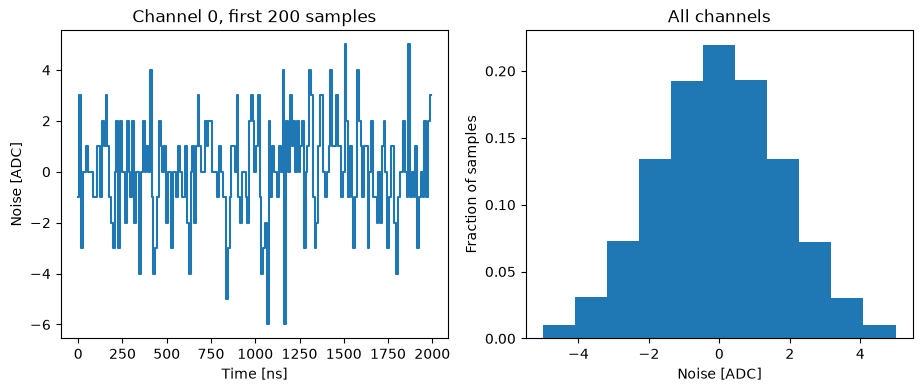

In [4]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.plot(np.arange(200) * sample_duration, noise[:200, 0], drawstyle="steps-mid")
left.set_xlabel("Time [ns]")
left.set_ylabel("Noise [ADC]")
left.set_title("Channel 0, first 200 samples")

right.hist(noise.flatten(), bins=11, range=(-5,5), density=True)
right.set_xlabel("Noise [ADC]")
right.set_ylabel("Fraction of samples")
right.set_title("All channels")
plt.show()

In [5]:
output_file = DUMMY_MAP_DIRECTORY / "noise_dummy.npz"
np.savez_compressed(output_file, arr_0=noise)
print("Saved", output_file, f"({output_file.stat().st_size / 1e6:.1f} MB)")

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/noise_dummy.npz (1.1 MB)
